In [1]:
import jax.numpy as jnp
import jax

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
from matplotlib.animation import FuncAnimation
from netgraph import Graph
from networkx.drawing.nx_pydot import graphviz_layout
import math

In [3]:
import numpy as np

In [4]:
map = {'0': '(',
       '1': ')'
      }

### Helper function

In [5]:
def show_graph_with_labels(adjacency_matrix, n_leaves, leaf_info = None, return_img = False):
    '''
      Shows the tree with label names. Adds distinct colors to the leave nodes and the ancestors of the leave nodes.

      Args:
        adjacency_matrix: adjacency matrix of the tree
        n_leaves: number of leaves in the tree
      Returns:
        None
    '''
    label_names = {}
    leaf_ids = []

    if(leaf_info != None):
        label_names = leaf_info[0]
        leaf_ids = leaf_info[1]
    else:
        # if label_names not provided, assuming perfect binary tree
        # assert n_leaves == 2**int(math.log2(n_leaves))

        for i in range(0,adjacency_matrix.shape[0]):
            label_names[i] = str(i)

        for i in range(0,n_leaves):
            leaf_ids.append(i)

    rows, cols = np.where(adjacency_matrix == 1)
    edges = zip(rows.tolist(), cols.tolist())


    gr = nx.DiGraph()#nx.DiGraph
    gr.add_edges_from(edges)

    color_map = []
    n_id = 0
    for node in gr:
        if(node not in leaf_ids):
            color_map.append('red')
        else:
            color_map.append('yellow')


    # color_map = ['red' if (node == 4 or node == 3) else 'yellow' for node in gr]
    fig = plt.figure(figsize = (n_leaves//2,n_leaves//2))
    # pos = graphviz_layout(gr, prog="dot")
    pos = nx.nx_agraph.graphviz_layout(gr, prog="dot")
    nx.draw(gr, pos, node_size = 250/math.log2(n_leaves), font_size=20/math.log2(n_leaves), labels = label_names, with_labels = True, node_color = color_map)
    # plt.close(fig)

    if(return_img):
        return fig
    else:
        fig.show()


In [6]:
def catalan(n):
    if (n == 0 or n == 1):
        return 1
 
    # Table to store results of subproblems
    catalan = [0 for i in range(n + 1)]
 
    # Initialize first two values in table
    catalan[0] = 1
    catalan[1] = 1
 
    # Fill entries in catalan[] using recursive formula
    for i in range(2, n + 1):
        catalan[i] = 0
        for j in range(i):
            catalan[i] += catalan[j] * catalan[i-j-1]
 
    # Return last entry
    return catalan[n]

In [7]:
def convert_parenthesis_notation_to_adj_matrix(tree_str):
  """
    Given a parenthesis string, generate the `adj_list` and `adj_matrix`

  """
  n_nodes = (len(tree_str)+1) # total number of nodes

  # node number we are currently at (left, bottom cell); we keep decreasing
  curr_node = n_nodes

  ## keep track of upcoming parents available, that we can utilize to add another child to the right
  parents_queue = [curr_node]

  adj_list = {}

  for j in range(0,len(tree_str)): # loop through the string
    pos = tree_str[j]
    curr_node -=1

    if(pos == "("):
      # we are essentially adding another parent candidate
      parent = parents_queue[-1]
    elif(pos == ")"):
      # we are essentially removing the chance of the poential parent being encountered again
      parents_queue.pop()
      parent = parents_queue[-1]
      parents_queue.pop()

    if(str(parent) not in adj_list.keys()):
      adj_list[str(parent)] = []

    adj_list[str(parent)].append(curr_node)
    parents_queue.append(curr_node)

  ## convert adjacency list to matrix
  adj_matrix = jnp.zeros((n_nodes, n_nodes))

  for key in adj_list.keys():
    for child in adj_list[key]:
      adj_matrix = adj_matrix.at[child-1, int(key)-1].set(1)

  return adj_matrix, adj_list

In [8]:
def generate_bifurcating_tree(seed,n_leaves):

  key1 = jax.random.key(seed)

  total_nodes = n_leaves*2 - 1
  total_edges = total_nodes - 1

  tree_str = ""

  l_count = 0
  r_count = 0

  iter = 0
  while(len(tree_str) < total_edges):
    ## loop until we have added all the edges

    val = jax.random.randint(key1, minval=0, maxval=2, shape= (1,))[0].item()
    key1, key2 = jax.random.split(key1)

    r_outcome = r_count + val
    l_outcome = l_count + (1 if val == 0 else 0)

    if(r_outcome > l_outcome or l_outcome > total_edges//2 or r_outcome > total_edges//2 ):
      continue
    else:
      tree_str += map[str(val)]
      r_count += val
      l_count += (1 if val == 0 else 0)

  return tree_str


### generating multiple trees (after cleaning the function)

In [9]:
def generate_random_tree_distribution(n_leaves, count, verbose = False):
    """
    Given the number of leaves needed, generate `count` number of random trees, save in hashmap
    
    Returns: 
        Return statistics of the tree distribution
    """

    hash_map = {}
    total_edges = (n_leaves*2 - 2)

    for seed in range(0,count):

        
        tree_str  = generate_bifurcating_tree(seed, n_leaves)
        adj_matrix, adj_list = convert_parenthesis_notation_to_adj_matrix(tree_str)
       
        if(verbose):
            print(tree_str)
            fig = show_graph_with_labels(adj_matrix, n_leaves, return_img = True)

        lower_indices = jnp.tril_indices(adj_matrix.shape[0])
        lower_triangle_sum = adj_matrix[lower_indices].sum()

        if(tree_str in hash_map.keys()):
            hash_map[tree_str] +=1
        else:
            hash_map[tree_str] = 1

        assert lower_triangle_sum == 0
        
    return catalan(total_edges//2), hash_map

In [10]:
cat_count, hash_map = generate_random_tree_distribution(4, 20)
cat_count, len(hash_map.keys()), hash_map

(5, 5, {'((()))': 8, '()()()': 2, '()(())': 4, '(()())': 3, '(())()': 3})

In [24]:
cat_count, hash_map = generate_random_tree_distribution(5, 1000)
cat_count, len(hash_map.keys()), hash_map

(14,
 14,
 {'((())())': 33,
  '()()()()': 103,
  '((()()))': 69,
  '()((()))': 123,
  '(()(()))': 70,
  '()(()())': 50,
  '(())()()': 63,
  '(((())))': 118,
  '(())(())': 69,
  '()()(())': 126,
  '()(())()': 76,
  '(()())()': 38,
  '((()))()': 24,
  '(()()())': 38})

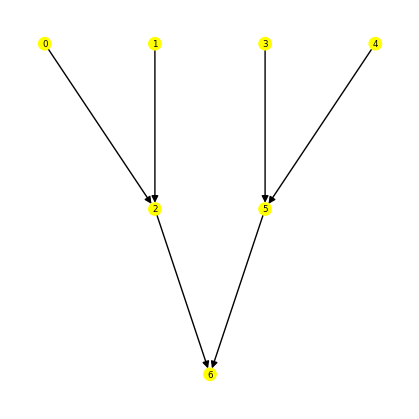

In [23]:
tree_str  = "(())()"
adj_matrix, adj_list = convert_parenthesis_notation_to_adj_matrix(tree_str)
fig = show_graph_with_labels(adj_matrix, n_leaves, return_img = True)

In [13]:
from functools import reduce

for i in range(2,10):
    n_leaves = i
    cat = catalan((2*n_leaves-2)//2)
    
    
    v = i*2-3
    print(f"n = {i}: Catalan : {cat}, Number of Bifurcating Topologies : {reduce(int.__mul__, range(v, 0, -2))}")
    

n = 2: Catalan : 1, Number of Bifurcating Topologies : 1
n = 3: Catalan : 2, Number of Bifurcating Topologies : 3
n = 4: Catalan : 5, Number of Bifurcating Topologies : 15
n = 5: Catalan : 14, Number of Bifurcating Topologies : 105
n = 6: Catalan : 42, Number of Bifurcating Topologies : 945
n = 7: Catalan : 132, Number of Bifurcating Topologies : 10395
n = 8: Catalan : 429, Number of Bifurcating Topologies : 135135
n = 9: Catalan : 1430, Number of Bifurcating Topologies : 2027025
